In [20]:
from dotenv import load_dotenv
load_dotenv

from langchain_tavily import TavilySearch

In [21]:
tool = TavilySearch(max_result=2)
tools = [tool]

In [22]:
tool.invoke("랭그래프에서 '노드'란 무엇인가요?")

{'query': "랭그래프에서 '노드'란 무엇인가요?",
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://velog.io/@jiyunwoo/LangGraph-%EC%9D%B4%EB%A1%A0-%EC%A0%95%EB%A6%AC',
   'title': 'LangGraph 이론 정리',
   'content': '`State`\n\n`StateGraph(State)`로 그래프를 생성하고, `add_node`로 노드를 추가한다\n\n`StateGraph(State)`\n`add_node`\n\n노드는 변경할 필드만 딕셔너리로 반환한다\n\n### 🟨 노드의 역할과 책임\n\nLangGraph에서 노드는 애플리케이션의 핵심 구성 요소로, 그래프 내에서 특정 작업을 수행하는 독립적인 처리 단위이다.\n\n노드의 가장 중요한 특징은 상태 중심 설계이다.\n\n노드의 주요 책임은 크게 세 가지로 나눌 수 있다.\n\nLangGraph의 노드는 모듈성과 재사용성을 강조한다.\n\n`TypedDict`\n`Annotated[list, operator.add]`\n\n서브그래프와 Private State 개념을 통해 더욱 복잡한 아키텍처도 지원한다\n\n노드는 또한 에러 처리와 복구에도 중요한 역할을 한다.\n\n노드는 성능 최적화의 핵심 단위이다. [...] ## 🟨 노드(Node)\n\n`def increment(state): # state라는 매개변수를 받는다 - 이는 현재 그래프 상태\nreturn {"counter": state["counter"] + 1} # state의 counter 값을 1 증가시킨 새로운 상태를 반환\ngraph.add_node("increment", increment) # 정의한 함수를 그래프의 노드로 추가\n# 첫 번째 인자: 노드의 이름\n# 두 번째 인자: 앞서 정의한 함수`\n\n🥨 노드의 역할\n\n→ 이렇게 정의된 노

In [23]:
from langchain.chat_models import init_chat_model

llm = init_chat_model("openai:gpt-4.1")
llm_with_tools = llm.bind_tools(tools)

In [24]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

def chatbot(state:State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

In [25]:
graph_builder.add_node("chatbot", chatbot)

In [26]:
# 도구 실행 노드 만들기 방법 1. 직접 노드를 정의 (BaiscToolNode)

import json
from langchain_core.messages import ToolMessage

class BasicToolNode:
    """챗봇이 요청한 도구를 실행하는 노드입니다."""

    def __init__(self, tools:list):
        self.tools_by_name = {tool.name: tool for tool in tools}

    def __call__(self, input:dict):
        messages = input.get("messages", [])
        if not messages:
            raise ValueError("입력된 상태에서 메시지를 찾을 수 없습니다.")
        outputs = []
        for tool_call in messages[-1].tool_calls:
            tool_result = self.tools_by_name[tool_call["name"]].invoke(tool_call["args"])
            outputs.append(
               ToolMessage(content=json.dumps(tool_result), name=tool_call["name"], tool_call_id=tool_call["id"]))
        return {"messages":outputs}

b_tool_node = BasicToolNode(tools=[tool])

In [27]:
# 방법 2. Prebuilt ToolNode 활용

from langgraph.prebuilt import ToolNode

tool_node = ToolNode(tools=[tool])

In [28]:
# 2번 방법의 노드를 추가함

graph_builder.add_node("tools", tool_node)

In [29]:
# 조건부 엣지 정의하기 tool call 여부로 판단

def route_tools(state:State):
    """
    마지막 챗봇 메세지에서 도구 호출(tool_calls)이 있는지 확인하여
    있으면 'tools'노드로, 없으면 종료(END)로 이동합니다.
    """
    ai_message = state["messages"][-1]

    if hasattr(ai_message, "tool_calls") and len(ai_message.tool_calls) > 0:
        return "tools" # 도구 호출이 있으면 도구 노드로 이동
    return END # 도구 호출이 없으면 종료

graph_builder.add_conditional_edges(
    "chatbot", route_tools, {"tools":"tools", END:END})

In [30]:
# 방법 2. tools_condition 활용 + 그래프 완성

from langgraph.prebuilt import tools_condition

graph_builder.add_conditional_edges(
    "chatbot", tools_condition
)

# 엣지 연결, 시작점 설정, 컴파일

# 도구 호출 후 챗봇으로 돌아가는 경로 설정
graph_builder.add_edge("tools", "chatbot")

# 그래프의 시작점 설정
graph_builder.add_edge(START,"chatbot")

# 그래프 완성 및 컴파일
graph = graph_builder.compile()

        +-----------+         
        | __start__ |         
        +-----------+         
               *              
               *              
               *              
          +---------+         
          | chatbot |         
          +---------+         
          .         *         
        ..           **       
       .               *      
+---------+         +-------+ 
| __end__ |         | tools | 
+---------+         +-------+ 


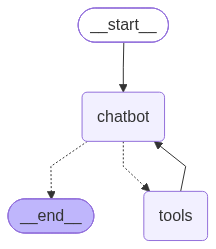

In [31]:
from IPython.display import Image, display

# 1. 아스키 아트로 텍스트 출력
print(graph.get_graph().draw_ascii())

# 2. 이미지(PNG)로 렌더링하여 화면에 표시
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
# 챗봇에게 질문하기 : 스트리밍 함수

def stream_graph_updates(user_input:str):
    for event in graph.stream({"messages":[{"role":"user", "content":user_input}]}):
        for value in event.values():
            print("Assistant:", value["messages"][-1].content)

In [33]:
# 챗봇에게 질문하기 : 대화 루프 실행

while True:
    user_input = input("User:")
    if user_input.lower() in ["quit", "exit", "q"]:
        print("Goodbye!")
        break

    stream_graph_updates(user_input)

Assistant: 안녕하세요! 무엇을 도와드릴까요? 😊
Assistant: 
Assistant: {"query": "오늘 서울 날씨", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://sharpweather.com/ko/seoul/today", "title": "오늘 서울 날씨 - 오늘 서울 날씨 시간별", "score": 0.9712385, "content": "En   Es   Ko\n\n 웹사이트용 위젯\n\n전 세계 날씨   서울\n\n오늘   내일   7일   주말\n\n# 오늘 서울 날씨\n\n일요일, 14 12월 2025\n\n일   13:00\n\n바람:  서, 4.4 m/s\n\n압력:  766 mmHg\n\n습도:  58 %\n\n구름 커버:  5 %\n\n밤   03:00\n\n맑음\n\n북서, 0.6 m/s\n\n769 mmHg\n\n74 %\n\n4 %\n\n일출 07:42\n\n일몰 17:11\n\n하루 기간 09 h 29 min\n\n## 오늘 서울 날씨 시간별\n\n00:00\n\n+2°C\n\n흐림\n\n바람:  북서, 2 m/s\n\n압력:  764 mmHg\n\n습도:  90 %\n\n구름 커버:  95 %\n\n01:00\n\n+4°C\n\n맑음\n\n서, 1.9 m/s\n\n764 mmHg\n\n92 %\n\n12 %\n\n02:00\n\n+4°C\n\n대체로 흐림\n\n북서, 2.7 m/s\n\n764 mmHg\n\n93 %\n\n73 %\n\n03:00\n\n+3°C\n\n흐림\n\n북서, 3.1 m/s\n\n764 mmHg\n\n90 %\n\n100 %\n\n04:00 [...] 90 %\n\n100 %\n\n04:00\n\n+2°C\n\n대체로 흐림\n\n북서, 3.7 m/s\n\n764 mmHg\n\n88 %\n\n59 %\n\n05:00\n\n+3°C\n\n맑음\n\n북서, 3.9 m/s\n\n764 m

In [34]:
# 메모리 체크 포인터 생성

from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver() # 실제 환경에서는 SQLite나 PostgreSQL을 사용하는 체크포인터로 교체하면 됨

In [35]:
graph = graph_builder.compile(checkpointer=memory)

In [36]:
config = {"configurable":{"thread_id":"1"}}
user_input = "안녕하세요! 제 이름은 랭체인입니다."

events = graph.stream(
    {"messages":[{"role":"user", "content":user_input}]}, config, stream_mode="values"
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

안녕하세요! 제 이름은 랭체인입니다.
================================== Ai Message ==================================

안녕하세요, 랭체인님! 만나서 반갑습니다. 오늘은 어떤 도움을 드릴까요? 😊


In [37]:
# 이전 대화 기억 확인

user_input = "내 이름이 뭐였나요?"

events = graph.stream(
    {"messages":[{"role":"user","content":user_input}]}, config, stream_mode="values"
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

내 이름이 뭐였나요?
================================== Ai Message ==================================

당신의 이름은 "랭체인"입니다! 😊  
혹시 더 궁금한 것이 있거나, 도움이 필요하시면 언제든 말씀해 주세요.
